# Telco Customer Churn: Exploratory Data Analysis (EDA)

This notebook explores the IBM Telco Customer Churn dataset (`data/WA_Fn-UseC_-Telco-Customer-Churn.csv`) to understand customer behaviors, service usage, billing dynamics, and churn risk factors. Findings from this exploration directly motivate our feature preprocessing, decision threshold optimization, and ethical modeling choices.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["font.size"] = 10


## 1. Dataset Shape and Data Types

In [2]:
data_path = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = pd.read_csv(data_path)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Column Data Types:")
print(df.dtypes)
df.head(3)


Dataset Shape: 7043 rows, 21 columns

Column Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 2. Missing Values & TotalCharges Blanks

In the raw CSV, `TotalCharges` is stored as an `object` type because blank whitespace entries (`" "`) represent missing values rather than explicit `NaN`s.


In [3]:
# Identify whitespace blanks in TotalCharges
blanks = df[df["TotalCharges"].str.strip() == ""]
print(f"Number of blank TotalCharges rows: {len(blanks)}")
print("Tenure values for blank TotalCharges rows:")
print(blanks[["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

# Clean and convert TotalCharges to float; tenure 0 customers have 0.0 total charges
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce").fillna(0.0)
print(f"\nMissing values per column after cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])


Number of blank TotalCharges rows: 11
Tenure values for blank TotalCharges rows:
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
3331  7644-OMVMY       0           19.85             
3826  3213-VVOLG       0           25.35             
4380  2520-SGTTA       0           20.00             
5218  2923-ARZLG       0           19.70             
6670  4075-WKNIU       0           73.35             
6754  2775-SEFEE       0           61.90             

Missing values per column after cleaning:
Series([], dtype: int64)


## 3. Overall Churn Rate & Class Imbalance

We inspect the class distribution of our target variable `Churn`.


Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall Churn Rate: 26.54%


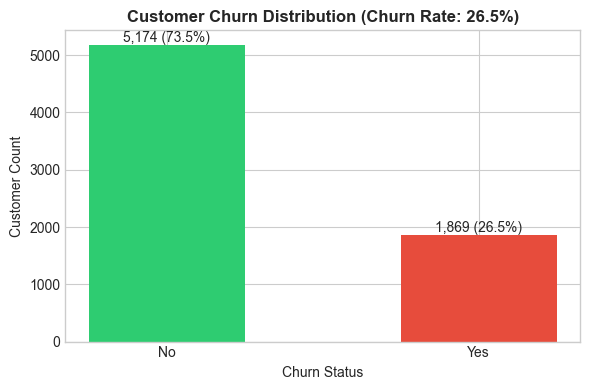

In [4]:
churn_counts = df["Churn"].value_counts()
churn_rate = (df["Churn"] == "Yes").mean() * 100

print(f"Churn Counts:\n{churn_counts}\n")
print(f"Overall Churn Rate: {churn_rate:.2f}%")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(churn_counts.index, churn_counts.values, color=["#2ecc71", "#e74c3c"], width=0.5)
ax.set_title(f"Customer Churn Distribution (Churn Rate: {churn_rate:.1f}%)", fontsize=12, fontweight="bold")
ax.set_ylabel("Customer Count")
ax.set_xlabel("Churn Status")
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 50, f"{yval:,} ({yval/len(df)*100:.1f}%)", ha="center")
plt.tight_layout()
plt.show()


## 4. Churn by Contract Type

Contract length is typically one of the strongest determinants of customer loyalty.


Churn Percentage by Contract Type:
Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.73  11.27
Two year        97.17   2.83


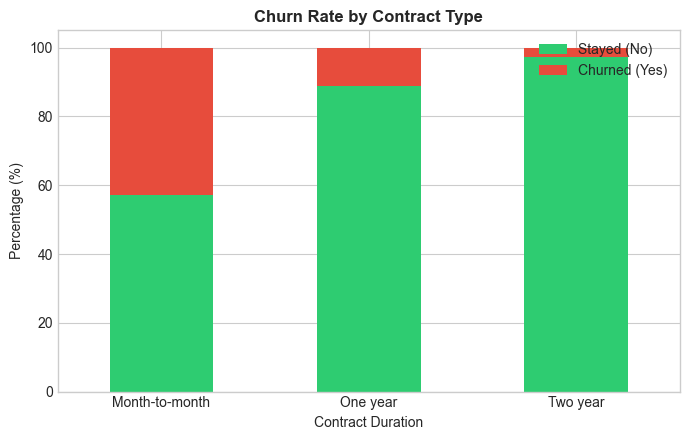

In [5]:
contract_churn = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
print("Churn Percentage by Contract Type:")
print(contract_churn.round(2))

ax = contract_churn.plot(kind="bar", stacked=True, color=["#2ecc71", "#e74c3c"], figsize=(7, 4.5))
ax.set_title("Churn Rate by Contract Type", fontsize=12, fontweight="bold")
ax.set_ylabel("Percentage (%)")
ax.set_xlabel("Contract Duration")
ax.legend(["Stayed (No)", "Churned (Yes)"], loc="upper right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Tenure Distribution by Churn Status

Examining how customer tenure (in months) relates to churn probability.


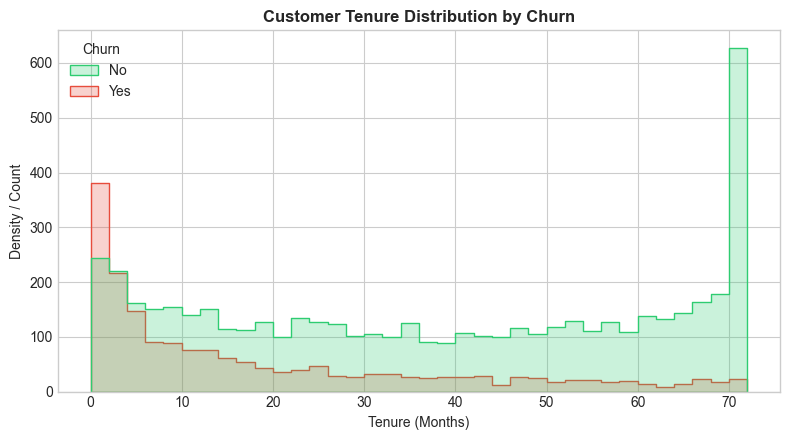

Median tenure for churned customers: 10.0 months
Median tenure for retained customers: 38.0 months


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df, x="tenure", hue="Churn", palette={"No": "#2ecc71", "Yes": "#e74c3c"},
             element="step", common_norm=False, bins=36, ax=ax)
ax.set_title("Customer Tenure Distribution by Churn", fontsize=12, fontweight="bold")
ax.set_xlabel("Tenure (Months)")
ax.set_ylabel("Density / Count")
plt.tight_layout()
plt.show()

print("Median tenure for churned customers:", df[df["Churn"] == "Yes"]["tenure"].median(), "months")
print("Median tenure for retained customers:", df[df["Churn"] == "No"]["tenure"].median(), "months")


## 6. Monthly Charges Distribution by Churn Status

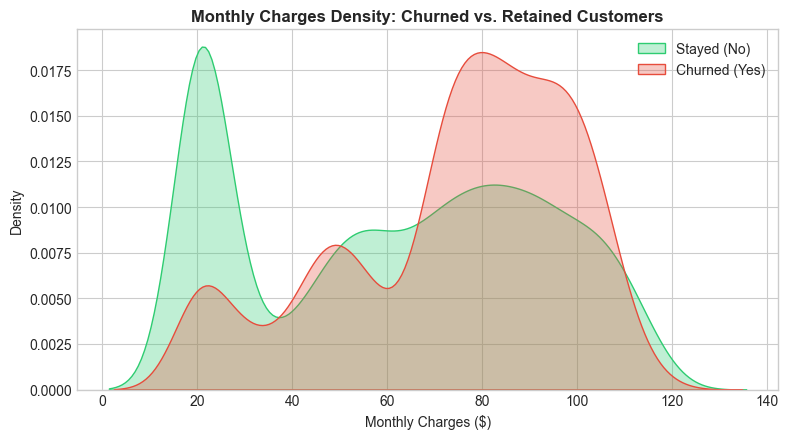

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.kdeplot(data=df[df["Churn"] == "No"]["MonthlyCharges"], label="Stayed (No)", color="#2ecc71", fill=True, alpha=0.3, ax=ax)
sns.kdeplot(data=df[df["Churn"] == "Yes"]["MonthlyCharges"], label="Churned (Yes)", color="#e74c3c", fill=True, alpha=0.3, ax=ax)
ax.set_title("Monthly Charges Density: Churned vs. Retained Customers", fontsize=12, fontweight="bold")
ax.set_xlabel("Monthly Charges ($)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Churn by Internet Service and Payment Method

C:\Users\abhinav\AppData\Local\Temp\ipykernel_23520\3302575112.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=internet_churn.values, y=internet_churn.index, palette="Reds_r", ax=ax1)
C:\Users\abhinav\AppData\Local\Temp\ipykernel_23520\3302575112.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=payment_churn.values, y=payment_churn.index, palette="Reds_r", ax=ax2)


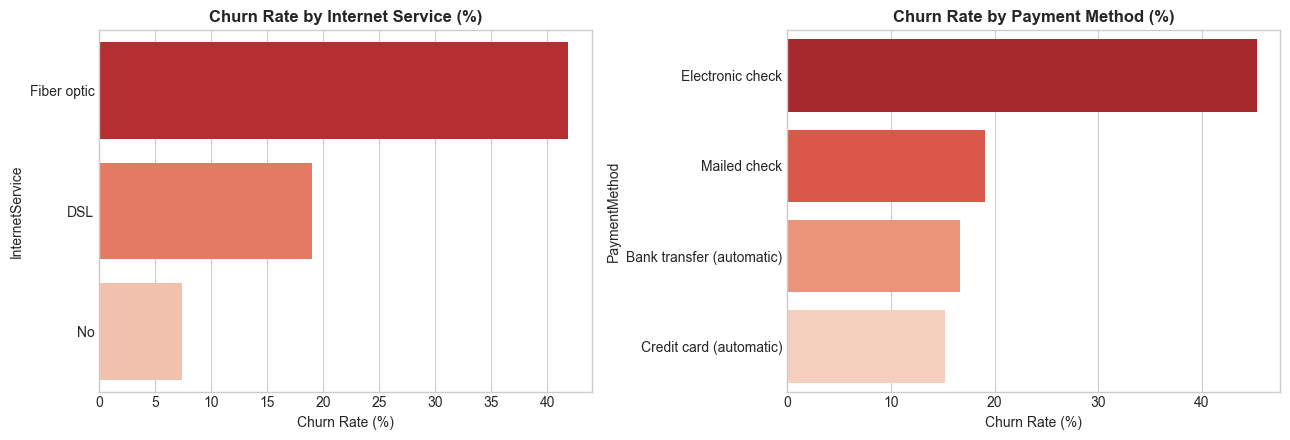

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

internet_churn = (pd.crosstab(df["InternetService"], df["Churn"], normalize="index")["Yes"] * 100).sort_values(ascending=False)
sns.barplot(x=internet_churn.values, y=internet_churn.index, palette="Reds_r", ax=ax1)
ax1.set_title("Churn Rate by Internet Service (%)", fontweight="bold")
ax1.set_xlabel("Churn Rate (%)")

payment_churn = (pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index")["Yes"] * 100).sort_values(ascending=False)
sns.barplot(x=payment_churn.values, y=payment_churn.index, palette="Reds_r", ax=ax2)
ax2.set_title("Churn Rate by Payment Method (%)", fontweight="bold")
ax2.set_xlabel("Churn Rate (%)")

plt.tight_layout()
plt.show()


## 8. Conclusions & Direct Modeling Decisions

Based on the empirical findings from this exploratory data analysis:

1. **Class Imbalance & Threshold Tuning:**
   - The overall churn rate is approximately **26.5%** (1,869 churners vs 5,174 retained customers).
   - In business terms, false negatives (failing to identify an at-risk customer who leaves) are far more costly than false positives (reaching out to a satisfied customer).
   - A standard default probability threshold of `0.5` causes gradient boosting and logistic regression models to miss many at-risk customers.
   - Consequently, our training pipeline tunes the decision threshold on out-of-fold cross-validation predictions to maximize the **F1 score** (yielding an optimal threshold of `0.348`), which significantly improves recall while maintaining precision.

2. **Exclusion of Gender as an Ethical Modeling Choice:**
   - Analysis shows virtually identical churn rates between male customers (~26.2%) and female customers (~26.9%).
   - Gender provides no predictive power and constitutes a protected demographic attribute.
   - To avoid direct reliance on a protected demographic attribute and eliminate demographic bias, `gender` is deliberately omitted from model features.

3. **Key Feature Drivers for Preprocessing:**
   - **Contract Type:** Month-to-month contracts exhibit a churn rate of ~42.7% versus ~2.8% for two-year contracts.
   - **Tenure:** First-year customers have the highest attrition probability.
   - **Internet & Billing:** Fiber optic service and Electronic Check payment methods correlate with elevated churn rates.
   - These continuous and categorical signals are scaled (`StandardScaler`) and encoded (`OneHotEncoder`) inside a unified `ColumnTransformer` to avoid data leakage.
